In [271]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


In [272]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [273]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [274]:
df = pd.read_csv('/content/creditcard.csv', on_bad_lines='skip')
display(df.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [275]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [276]:
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Dataset shape: (290738, 31)
Total rows: 290738
Total columns: 31


In [277]:
print(df.columns)

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')


In [278]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290738 entries, 0 to 290737
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    290738 non-null  float64
 1   V1      290738 non-null  float64
 2   V2      290738 non-null  float64
 3   V3      290738 non-null  float64
 4   V4      290738 non-null  float64
 5   V5      290738 non-null  float64
 6   V6      290738 non-null  float64
 7   V7      290738 non-null  float64
 8   V8      290738 non-null  float64
 9   V9      290738 non-null  float64
 10  V10     290738 non-null  float64
 11  V11     290738 non-null  float64
 12  V12     290738 non-null  float64
 13  V13     290738 non-null  float64
 14  V14     290738 non-null  float64
 15  V15     290738 non-null  float64
 16  V16     290738 non-null  float64
 17  V17     290738 non-null  float64
 18  V18     290738 non-null  float64
 19  V19     290738 non-null  float64
 20  V20     290738 non-null  float64
 21  V21     29

In [279]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,290738.000000,290738.000000,290738.000000,290738.000000,290738.000000,290738.000000,290738.000000,290738.000000,290738.000000,290738.000000,...,290738.000000,290738.000000,290738.000000,290737.000000,290737.000000,290737.000000,290737.000000,290736.000000,290736.000000,290736.000000
mean,95597.874647,0.002349,0.001676,-0.003776,-0.001366,0.001529,-0.001273,0.001450,0.000256,-0.001474,...,-0.000588,0.000296,0.000374,-0.000419,-0.001261,-0.000329,0.000454,-0.000319,88.131696,0.001716
std,47734.682874,1.956588,1.648807,1.516250,1.414956,1.392568,1.337720,1.252668,1.191029,1.096418,...,0.733017,0.798769,0.623033,0.605634,0.521207,0.490139,0.406576,0.329820,253.596160,0.041393
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54813.250000,-0.919074,-0.596725,-0.895390,-0.847862,-0.689038,-0.769183,-0.552955,-0.208388,-0.642616,...,-0.228901,-0.543282,-0.161664,-0.355536,-0.318381,-0.327178,-0.070695,-0.053044,5.490000,0.000000
50%,85319.000000,0.018358,0.066546,0.175001,-0.021763,-0.052551,-0.275953,0.041305,0.022227,-0.052161,...,-0.029919,0.005717,-0.010619,0.040685,0.014065,-0.051799,0.001484,0.011132,21.980000,0.000000
75%,140338.000000,1.317639,0.806032,1.023947,0.738863,0.613478,0.395281,0.571870,0.327138,0.594789,...,0.186406,0.529022,0.148388,0.439839,0.349585,0.240429,0.091458,0.078289,76.950000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,179.790000,22.528412,4.584549,7.519589,46.970000,31.612198,33.847808,25691.160000,1.000000


In [280]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [281]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 7010


In [282]:
df['Class'].value_counts()

,count
Class,
0.0,290237
1.0,499


In [283]:
df['Class'].value_counts()

,count
Class,
0.0,290237
1.0,499


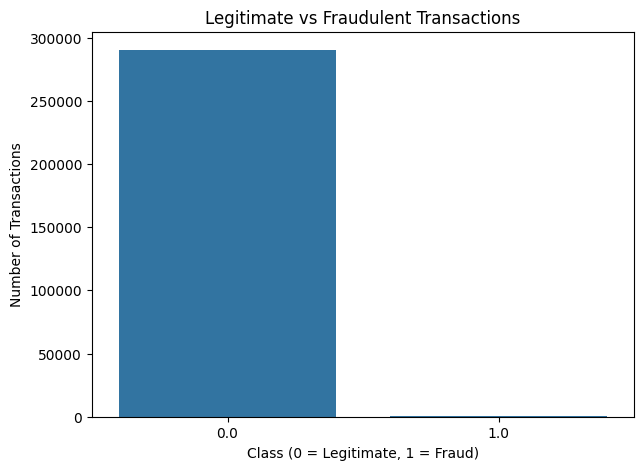

In [284]:
plt.figure(figsize=(7, 5))

sns.countplot(x='Class', data=df)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [285]:
class_percentage = df['Class'].value_counts(normalize=True) * 100

print("Class distribution in percentage:")
print(class_percentage)

Class distribution in percentage:
Class
0.0    99.828367
1.0     0.171633
Name: proportion, dtype: float64


In [286]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       1
V25       1
V26       1
V27       1
V28       2
Amount    2
Class     2
dtype: int64

Total missing values: 10


In [287]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Dataset shape after removing duplicates: (283728, 31)
Duplicates remaining: 0


In [288]:
df = df.dropna()

print("Dataset shape after removing missing values:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

Dataset shape after removing missing values: (283726, 31)
Missing values remaining: 0


In [289]:
print("Class distribution after cleaning:")
print(df['Class'].value_counts())

Class distribution after cleaning:
Class
0.0    283253
1.0       473
Name: count, dtype: int64


In [290]:
# Separate input features and target variable

X = df.drop('Class', axis=1)
y = df['Class']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (226980, 30)
Testing features: (56746, 30)

Training target: (226980,)
Testing target: (56746,)


In [ ]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

In [ ]:
print("Intercept:", model.intercept_)
print("Number of coefficients:", len(model.coef_[0]))

In [ ]:
# Predict probability of fraud
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Predict class labels
y_pred = model.predict(X_test_scaled)

print("Predictions completed successfully!")
print("Total predictions:", len(y_pred))

In [ ]:
import pandas as pd

results = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred,
    'Fraud Probability': y_prob
})

print(results.head(10))

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted Legitimate (0)', 'Predicted Fraud (1)'],
    yticklabels=['Actual Legitimate (0)', 'Actual Fraud (1)']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Calculate specificity
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall (Sensitivity):", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)

In [ ]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - Credit Card Fraud Detection')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds_to_test = [0.3, 0.5, 0.7]

for threshold in thresholds_to_test:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    print(f"\n--- Threshold: {threshold} ---")
    print("Accuracy :", accuracy_score(y_test, y_threshold_pred))
    print("Precision:", precision_score(y_test, y_threshold_pred, zero_division=0))
    print("Recall   :", recall_score(y_test, y_threshold_pred, zero_division=0))
    print("F1 Score :", f1_score(y_test, y_threshold_pred, zero_division=0))
    print("Frauds predicted:", y_threshold_pred.sum())

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

threshold_results = []

for threshold in thresholds_to_test:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_threshold_pred),
        'Precision': precision_score(y_test, y_threshold_pred, zero_division=0),
        'Recall': recall_score(y_test, y_threshold_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_threshold_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

threshold_df.set_index('Threshold')[['Precision', 'Recall', 'F1 Score']].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Performance Comparison at Different Thresholds')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict on training data
y_train_pred = model.predict(X_train_scaled)

# Training metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred, zero_division=0)
train_recall = recall_score(y_train, y_train_pred, zero_division=0)
train_f1 = f1_score(y_train, y_train_pred, zero_division=0)

# Testing metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, zero_division=0)
test_recall = recall_score(y_test, y_pred, zero_division=0)
test_f1 = f1_score(y_test, y_pred, zero_division=0)

# Display comparison
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Training': [train_accuracy, train_precision, train_recall, train_f1],
    'Testing': [test_accuracy, test_precision, test_recall, test_f1]
})

print(comparison.round(4))

In [ ]:
comparison.set_index('Metric')[['Training', 'Testing']].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Training vs Testing Performance')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()